In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Chargement des reservations nettoyees 
df = pd.read_csv("../nettoyage_des_donnees/Valmont_cleaned.csv")

# 2. Selection des 5 variables comportementales 
features = ["nb_nuits", "nb_personnes", "delai_reservation_j", "prix_nuit_eur", "nuitees_cumulees_client"]
X = df[features].dropna()


# 3. Standardisation 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Données chargées et standardisées : {X_scaled.shape[0]} réservations et {X_scaled.shape[1]} variables.")

Données chargées et standardisées : 794 réservations et 5 variables.


--- Évaluation des valeurs de k ---
k=2 | Inertie = 3204.25 | Score de Silhouette = 0.257
k=3 | Inertie = 2640.88 | Score de Silhouette = 0.268
k=4 | Inertie = 2182.01 | Score de Silhouette = 0.274
k=5 | Inertie = 1871.01 | Score de Silhouette = 0.278
k=6 | Inertie = 1641.37 | Score de Silhouette = 0.275
k=7 | Inertie = 1546.15 | Score de Silhouette = 0.271
k=8 | Inertie = 1459.81 | Score de Silhouette = 0.221
k=9 | Inertie = 1379.48 | Score de Silhouette = 0.218

Gains d'inertie d'un k au suivant :
Passage de k=2 à k=3 : Gain d'inertie = 563.37
Passage de k=3 à k=4 : Gain d'inertie = 458.86
Passage de k=4 à k=5 : Gain d'inertie = 311.00
Passage de k=5 à k=6 : Gain d'inertie = 229.64
Passage de k=6 à k=7 : Gain d'inertie = 95.22
Passage de k=7 à k=8 : Gain d'inertie = 86.34
Passage de k=8 à k=9 : Gain d'inertie = 80.34


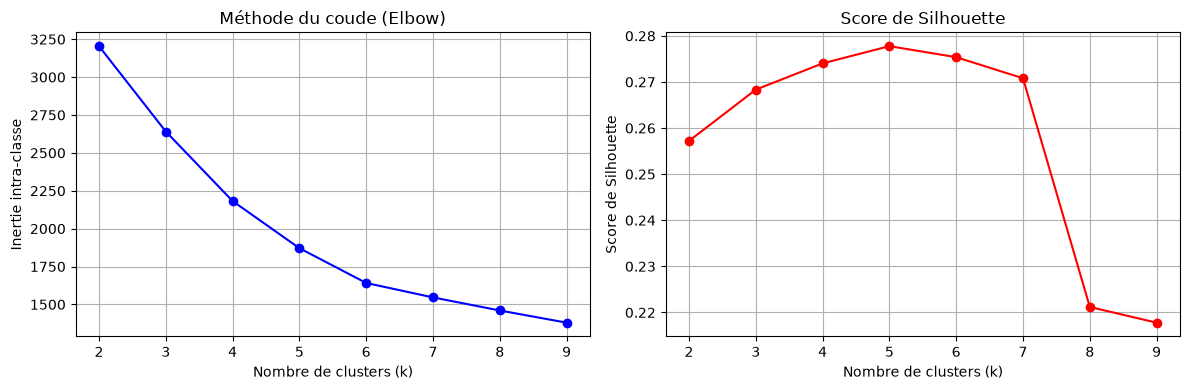

In [113]:
# Recherche du nombre optimal de clusters (k)

inerties = []
silhouettes = []
k_range = range (2, 10)

print("--- Évaluation des valeurs de k ---")
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inerties.append(kmeans.inertia_)
    sil = silhouette_score(X_scaled, labels)
    silhouettes.append(sil)
    print(f"k={k} | Inertie = {kmeans.inertia_:.2f} | Score de Silhouette = {sil:.3f}")

print("\nGains d'inertie d'un k au suivant :")
for i in range(len(inerties) - 1):
    gain = inerties[i] - inerties[i+1]
    print(f"Passage de k={k_range[i]} à k={k_range[i+1]} : Gain d'inertie = {gain:.2f}")

# Visualisation des graphiques (Coude et Silhouette)
plt.figure(figsize=(12, 4))

# 1. Graphique du Coude (Inertie intra-classe)
plt.subplot(1, 2, 1)
plt.plot(k_range, inerties, "bo-")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie intra-classe")
plt.title("Méthode du coude (Elbow)")
plt.grid(True)

# 2. Graphique de la Silhouette
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouettes, "ro-")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Score de Silhouette")
plt.title("Score de Silhouette")
plt.grid(True)

plt.tight_layout()
plt.show()

In [114]:
# Analyse du taux d'annulation et de la part 5 étoiles à k=5 pour justifier le passage à k=6
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df["cluster_5"] = kmeans_5.fit_predict(X_scaled)

print("--- Taux d'annulation par cluster pour k=5 (%) ---")
annul_k5 = (df["a_annule"].astype(str).str.lower() == "oui").groupby(df["cluster_5"]).mean() * 100
print(annul_k5.round(1))
print(f"Taux d'annulation maximal observé à k=5 : {annul_k5.max():.1f}%")

print("\n--- Part des Hôtels 5 Étoiles par cluster pour k=5 (%) ---")
is_5_k5 = df["categorie"].astype(str).str.contains("5")
print((is_5_k5.groupby(df["cluster_5"]).mean() * 100).round(1))

--- Taux d'annulation par cluster pour k=5 (%) ---
cluster_5
0    20.5
1    36.3
2    33.8
3    23.5
4    18.7
Name: a_annule, dtype: float64
Taux d'annulation maximal observé à k=5 : 36.3%

--- Part des Hôtels 5 Étoiles par cluster pour k=5 (%) ---
cluster_5
0      0.0
1     28.9
2     12.2
3    100.0
4     17.3
Name: categorie, dtype: float64


In [115]:
# 1. Définition du nombre optimal de clusters retenu (k=6)
k_optimal = 6

# 2. Entraînement de K-Means et affectation du cluster à chaque réservation
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df["cluster"] = kmeans_final.fit_predict(X_scaled)

# 3. Volume par cluster
print("Effectifs par cluster (k=6) :")
print(df["cluster"].value_counts().sort_index())

# 4. Profils moyens (centroïdes)
print("\nProfils moyens des clusters (variables comportementales) :")
profils = df.groupby("cluster")[features].mean()
print(profils.round(2))

# 5. Amplitudes de la durée de séjour (min, moyenne, max)
print("\nMin, Moyenne et Max de nb_nuits par cluster (étayage du seuil de 4 nuits) :")
print(df.groupby("cluster")["nb_nuits"].agg(["min", "mean", "max"]))

Effectifs par cluster (k=6) :
cluster
0    137
1    238
2    119
3    144
4     71
5     85
Name: count, dtype: int64

Profils moyens des clusters (variables comportementales) :
         nb_nuits  nb_personnes  delai_reservation_j  prix_nuit_eur  \
cluster                                                               
0            5.04          1.79                38.72         145.08   
1            2.17          1.38                20.67         140.48   
2            2.39         11.86                55.87         184.06   
3            2.83          1.74                29.05         366.22   
4            2.39          2.23                27.17         174.60   
5            3.19          3.18               123.79         175.40   

         nuitees_cumulees_client  
cluster                           
0                           9.25  
1                           8.80  
2                           8.11  
3                          10.43  
4                          29.11  
5       

In [116]:
# Analyse du segment déclaré 

print("Répartition des segments déclarés par cluster (% en ligne - profil du cluster) :")
print((pd.crosstab(df["cluster"], df["segment_declare"], normalize="index") * 100).round(1))

print("\nRépartition des segments déclarés par cluster (% en colonne - captation du segment) :")
print((pd.crosstab(df["cluster"], df["segment_declare"], normalize="columns") * 100).round(1))

Répartition des segments déclarés par cluster (% en ligne - profil du cluster) :
segment_declare  affaires  groupe  loisir
cluster                                  
0                    29.2     2.2    68.6
1                    68.9     1.7    29.4
2                     0.0   100.0     0.0
3                    50.7     3.5    45.8
4                    57.7     9.9    32.4
5                     0.0    14.1    85.9

Répartition des segments déclarés par cluster (% en colonne - captation du segment) :
segment_declare  affaires  groupe  loisir
cluster                                  
0                    12.6     2.0    28.8
1                    51.6     2.7    21.5
2                     0.0    79.3     0.0
3                    23.0     3.3    20.2
4                    12.9     4.7     7.1
5                     0.0     8.0    22.4


In [117]:
# Tableau de croisement métier par cluster (Q8)

croisement = pd.DataFrame()
croisement["Effectif"] = df["cluster"].value_counts().sort_index()

# 1. Taux d'annulation par groupe
croisement["Taux Annulation (%)"] = ((df["a_annule"].astype(str).str.lower() == "oui").groupby(df["cluster"]).mean() * 100).round(1)

# 2. Part des réservations et nuitées hors week-end (toutes réservations)
is_weekend = df["weekend"].astype(str).str.lower() == "oui"
croisement["Part Reservations Week-end (%)"] = (is_weekend.groupby(df["cluster"]).mean() * 100).round(1)

df["nuits_hors_weekend"] = df["nb_nuits"] * (~is_weekend)
croisement["Nuits Hors Week-end Total"] = df.groupby("cluster")["nuits_hors_weekend"].sum().round(0)
croisement["Part Nuitees Hors Week-end (%)"] = ((df.groupby("cluster")["nuits_hors_weekend"].sum() / df.groupby("cluster")["nb_nuits"].sum()) * 100).round(1)

# 3. Part des réservations en Hôtels 5 Étoiles
is_5_etoiles = df["categorie"].astype(str).str.contains("5")
croisement["Part Hotels 5 Etoiles (%)"] = (is_5_etoiles.groupby(df["cluster"]).mean() * 100).round(1)

# 4. Part du petit-déjeuner
croisement["Part Petit Dejeuner (%)"] = ((df["petit_dejeuner"].astype(str).str.lower() == "oui").groupby(df["cluster"]).mean() * 100).round(1)

# 5. Borne haute du chiffre d'affaires annulé par cluster
df["ca_reservation"] = df["nb_nuits"] * df["prix_nuit_eur"]
df["ca_annule"] = np.where(df["a_annule"].astype(str).str.lower() == "oui", df["ca_reservation"], 0)
croisement["CA Annule Total (EUR)"] = df.groupby("cluster")["ca_annule"].sum().round(0)

print("Tableau de croisement métier par cluster :")
print(croisement)

# Impression du total du CA annulé et de la part du groupe 5
total_ca_annule = df["ca_annule"].sum()
part_grp5_ca = (df.groupby("cluster")["ca_annule"].sum().loc[5] / total_ca_annule * 100).round(1)
print(f"\nChiffre d'affaires total annulé (borne haute) : {total_ca_annule:,.0f} €")
print(f"Part du Groupe 5 (Planificateurs) dans le CA annulé : {part_grp5_ca}%")

# Distribution du canal de réservation
print("\nDistribution du canal de réservation par cluster (% en ligne) :")
ct_canal = (pd.crosstab(df["cluster"], df["canal"], normalize="index") * 100).round(1)
print(ct_canal)
print(f"Plage OTA : min = {ct_canal['OTA'].min()}% | max = {ct_canal['OTA'].max()}%")

# 6. Complément Q8 : Remplissage hors week-end sur réservations VALIDÉES uniquement (non annulées)
is_non_annule = df["a_annule"].astype(str).str.lower() == "non"
df_valides = df[is_non_annule].copy()

nuits_hw_valides = df_valides.groupby("cluster")["nuits_hors_weekend"].sum()
total_hw_valides = nuits_hw_valides.sum()
pct_hw_valides = (nuits_hw_valides / total_hw_valides * 100).round(1)

tot_nuits_cluster_valides = df_valides.groupby("cluster")["nb_nuits"].sum()
pct_nuits_cluster_hw_valides = (nuits_hw_valides / tot_nuits_cluster_valides * 100).round(1)

print("\n=== Nuitées Hors Week-end sur Réservations Validées (Non Annulées) ===")
res_valides_df = pd.DataFrame({
    "Nuits HW (Validées)": nuits_hw_valides,
    "Part du Volume Total HW (%)": pct_hw_valides,
    "Part au sein du Cluster HW (%)": pct_nuits_cluster_hw_valides
})
print(res_valides_df)
print(f"\nTotal des nuitées hors week-end validées : {total_hw_valides} nuitées")
print(f"Part du Groupe 0 (Longs Séjours) sur le total validé : {pct_hw_valides.loc[0]}%")


Tableau de croisement métier par cluster :
         Effectif  Taux Annulation (%)  Part Reservations Week-end (%)  \
cluster                                                                  
0             137                 28.5                            25.5   
1             238                 18.5                            31.9   
2             119                 31.9                            24.4   
3             144                 22.2                            38.2   
4              71                 19.7                            31.0   
5              85                 47.1                            37.6   

         Nuits Hors Week-end Total  Part Nuitees Hors Week-end (%)  \
cluster                                                              
0                              516                            74.8   
1                              351                            67.9   
2                              211                            74.0   
3             

In [118]:
# Renommage commercial et Exportation local unique pour Lina (Tâche 6)

# 1. Dictionnaire des noms commerciaux attribués aux 6 clusters
dico_noms = {
    0: "Longs Séjours",
    1: "Voyageurs Économiques",
    2: "Groupes & Séminaires",
    3: "Clientèle Premium",
    4: "Clients Fidèles",
    5: "Planificateurs Anticipés" 
}

# 2. Application du dictionnaire au DataFrame principal
df["nom_segment"] = df["cluster"].map(dico_noms)

print("Les segments ont été correctement attribués :")
print(df[["cluster", "nom_segment"]].head(10))

# 3. Exportation unique du dataset enrichi dans le dossier local segmentation_clients
df.to_csv("Valmont_with_clusters.csv", index=False)
print("\nLe fichier 'Valmont_with_clusters.csv' a été exporté avec succès dans 'segmentation_clients/' pour Lina (Tâche 6) !")

Les segments ont été correctement attribués :
   cluster               nom_segment
0        2      Groupes & Séminaires
1        1     Voyageurs Économiques
2        3         Clientèle Premium
3        0             Longs Séjours
4        5  Planificateurs Anticipés
5        2      Groupes & Séminaires
6        0             Longs Séjours
7        1     Voyageurs Économiques
8        3         Clientèle Premium
9        3         Clientèle Premium

Le fichier 'Valmont_with_clusters.csv' a été exporté avec succès dans 'segmentation_clients/' pour Lina (Tâche 6) !
